<a href="https://colab.research.google.com/github/jaska12/computer_vision/blob/main/3_menu_detector_test.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 3-qism: Menu Detector — test qilish
Avval `menu_detector.pth` faylini chap paneldagi 📁 **Files** bo'limiga yuklang
(yoki pastdagi 0-katak orqali Drive'dan oling). Keyin asosiy katakni ishga tushirib, taom rasmini yuklang.

### 0. (Ixtiyoriy) Modelni Google Drive'dan olish
`menu_detector.pth` ni qo'lda yuklamagan bo'lsangiz, shu katakni ishga tushiring.

In [1]:
from google.colab import drive
import shutil
drive.mount('/content/drive')
shutil.copy('/content/drive/MyDrive/menu_detector.pth', '/content/menu_detector.pth')
print("✅ menu_detector.pth /content ga ko'chirildi")

Mounted at /content/drive
✅ menu_detector.pth /content ga ko'chirildi


### 1. Modelni yuklash va rasm bo'yicha bashorat qilish

device: cuda
Upload one or more images of hamburger or hot dog:


Saving pilof.webp to pilof.webp


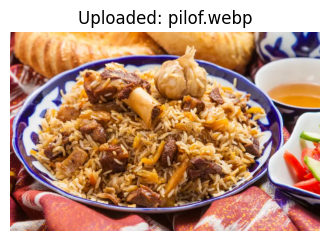

Prediction:
  ✅ hot_dog: 40.98%
  ✅ pilaf: 31.98%
  ✅ hamburger: 21.96%
  ✅ dessert: 3.20%


In [2]:
# -----------------------------------------
# Required Imports
# -----------------------------------------
import torch
import torchvision.transforms as transforms
from torchvision.models import mobilenet_v2
from PIL import Image
from google.colab import files
import io
import matplotlib.pyplot as plt

# -----------------------------------------
# Define Semantic Classes
# -----------------------------------------
CLASSES = ['hamburger', 'hot_dog', 'dessert', 'kebab', 'pilaf']  # Must match training order
NUM_CLASSES = len(CLASSES)
CLASS_TO_IDX = {cls: i for i, cls in enumerate(CLASSES)}

# -----------------------------------------
# Transform for Uploaded Images (no augmentations!)
# -----------------------------------------
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# -----------------------------------------
# Load Model
# -----------------------------------------
model = mobilenet_v2(weights=None)
model.classifier[1] = torch.nn.Linear(model.classifier[1].in_features, NUM_CLASSES)
model.load_state_dict(torch.load('/content/menu_detector.pth', map_location='cpu'))

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)
model = model.to(device)
model.eval()

# -----------------------------------------
# Upload & Predict
# -----------------------------------------
print("Upload one or more images of hamburger or hot dog:")
uploaded = files.upload()

for image_name in uploaded.keys():
    image = Image.open(io.BytesIO(uploaded[image_name])).convert('RGB')

    # Display image
    plt.figure(figsize=(4, 4))
    plt.imshow(image)
    plt.axis('off')
    plt.title(f'Uploaded: {image_name}')
    plt.show()

    # Predict
    image_tensor = transform(image).unsqueeze(0).to(device)
    with torch.no_grad():
        output = model(image_tensor)
        probs = torch.softmax(output, dim=1)[0]
        topk = torch.topk(probs, 4)

    print("Prediction:")
    for i in range(topk.indices.size(0)):
        label = CLASSES[topk.indices[i]]
        confidence = topk.values[i].item() * 100
        print(f"  ✅ {label}: {confidence:.2f}%")